In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
np.random.seed(42)

print("Libraries imported successfully!")
n = 200

study_hours = np.clip(np.random.normal(4.5, 2, n), 0.5, 10)
attendance = np.clip(np.random.normal(80, 10, n), 40, 100)
previous_score = np.clip(np.random.normal(65, 12, n), 20, 100)

# Scores partly influenced by study hours, attendance and previous performance
noise = np.random.normal(0, 8, n)

math_score = np.clip(
    20 + 4 * study_hours + 0.20 * attendance
    + 0.25 * previous_score + noise,
    0, 100
)

reading_score = np.clip(
    25 + 2.5 * study_hours + 0.20 * attendance
    + 0.35 * previous_score + np.random.normal(0, 8, n),
    0, 100
)

writing_score = np.clip(
    20 + 3 * study_hours + 0.18 * attendance
    + 0.40 * previous_score + np.random.normal(0, 9, n),
    0, 100
)

df = pd.DataFrame({
    "student_id": range(1, n + 1),
    "gender": np.random.choice(["Female", "Male"], n),
    "parent_education": np.random.choice(
        ["High School", "Bachelor's", "Master's"], n
    ),
    "study_hours": study_hours,
    "attendance": attendance,
    "previous_score": previous_score,
    "math_score": math_score,
    "reading_score": reading_score,
    "writing_score": writing_score
})

df.loc[0, "math_score"] = 250
df.loc[1, "reading_score"] = -30
df.loc[2, "study_hours"] = 60

df.to_csv("student_exam_performance.csv", index=False)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Libraries imported successfully!
Dataset created successfully!
Dataset shape: (200, 9)


,student_id,gender,parent_education,study_hours,attendance,previous_score,math_score,reading_score,writing_score
0,1,Male,Bachelor's,5.493428,83.577874,45.866868,250.000000,79.008820,82.465248
1,2,Female,Bachelor's,4.223471,85.607845,57.807500,61.090007,-30.000000,79.524529
2,3,Male,High School,60.000000,90.830512,65.062924,84.570189,81.195535,80.297467
3,4,Female,Bachelor's,7.546060,90.538021,65.563767,95.527888,81.221870,79.338099
4,5,Female,High School,4.031693,66.223306,59.599214,67.578717,65.707650,74.138970


In [18]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nNumerical summary:")
display(df.describe().round(2))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        200 non-null    int64  
 1   gender            200 non-null    object 
 2   parent_education  200 non-null    object 
 3   study_hours       200 non-null    float64
 4   attendance        200 non-null    float64
 5   previous_score    200 non-null    float64
 6   math_score        200 non-null    float64
 7   reading_score     200 non-null    float64
 8   writing_score     200 non-null    float64
dtypes: float64(6), int64(1), object(2)
memory usage: 14.2+ KB

Missing values:


,Missing Values
student_id,0
gender,0
parent_education,0
study_hours,0
attendance,0
previous_score,0
math_score,0
reading_score,0
writing_score,0



Numerical summary:


,student_id,study_hours,attendance,previous_score,math_score,reading_score,writing_score
count,200.00,200.00,200.00,200.00,200.00,200.00,200.00
mean,100.50,4.70,80.71,63.96,70.76,75.12,74.51
std,57.88,4.34,9.48,11.90,17.32,12.14,10.80
min,1.00,0.50,47.59,35.34,41.12,-30.00,42.67
25%,50.75,3.09,73.94,55.47,62.18,69.35,68.49
50%,100.50,4.49,80.79,64.07,69.34,75.82,74.17
75%,150.25,5.50,86.87,71.87,77.52,81.67,81.94
max,200.00,60.00,100.00,100.00,250.00,100.00,100.00


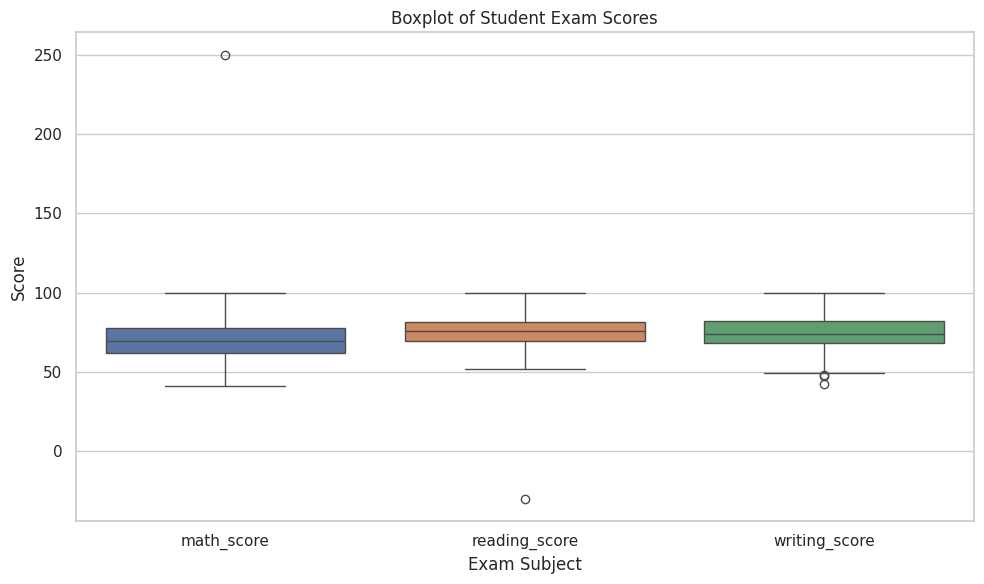

In [19]:
score_columns = ["math_score","reading_score","writing_score"]
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[score_columns])
plt.title("Boxplot of Student Exam Scores")
plt.ylabel("Score")
plt.xlabel("Exam Subject")
plt.tight_layout()
plt.savefig("boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

In [20]:
outlier_results = []

for col in score_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    )

    outlier_results.append({
        "Feature": col,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": int(outlier_mask.sum())
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,math_score,62.18,77.52,15.34,39.16,100.54,1
1,reading_score,69.35,81.67,12.33,50.85,100.17,1
2,writing_score,68.49,81.94,13.45,48.31,102.12,3


In [21]:
df_clean = df.copy()

for col in score_columns:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    df_clean[col] = df_clean[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

print("Original extreme scores:")
display(df[score_columns].iloc[:3])

print("Scores after capping:")
display(df_clean[score_columns].iloc[:3])

Original extreme scores:


,math_score,reading_score,writing_score
0,250.000000,79.008820,82.465248
1,61.090007,-30.000000,79.524529
2,84.570189,81.195535,80.297467


Scores after capping:


,math_score,reading_score,writing_score
0,100.538570,79.008820,82.465248
1,61.090007,50.853351,79.524529
2,84.570189,81.195535,80.297467


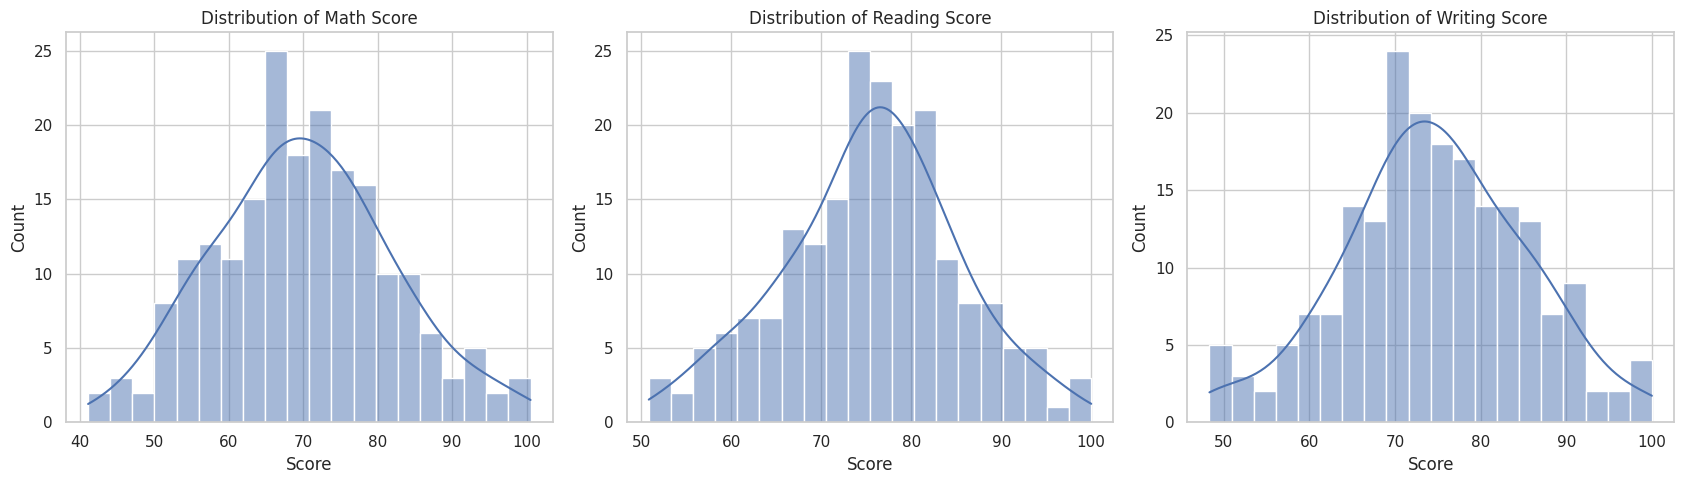

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, col in zip(axes, score_columns):
    sns.histplot(
        data=df_clean,
        x=col,
        kde=True,
        bins=20,
        ax=ax
    )
    ax.set_title(f"Distribution of {col.replace('_', ' ').title()}")
    ax.set_xlabel("Score")

plt.tight_layout()
plt.savefig("distribution_plot.png", dpi=300, bbox_inches="tight")
plt.show()

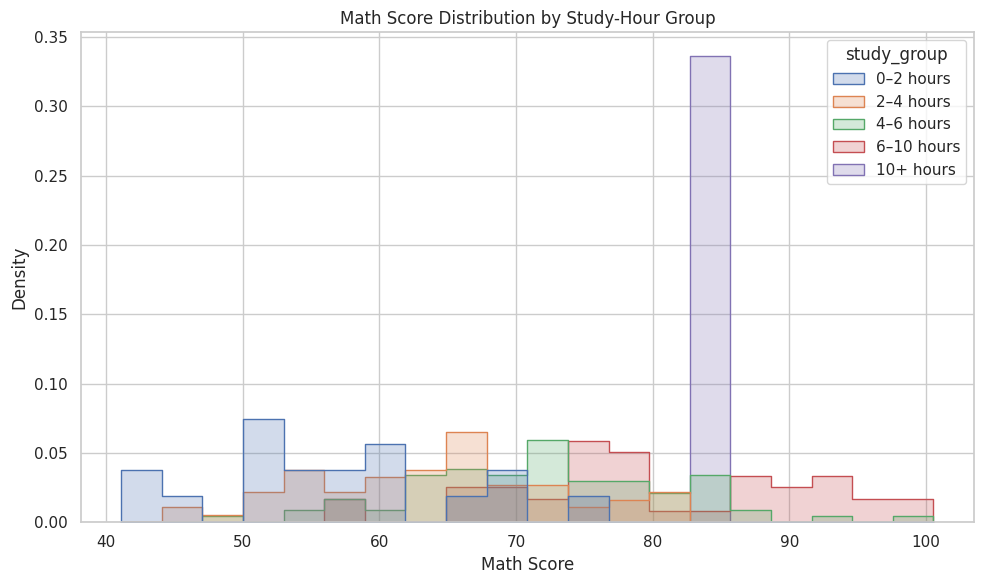

In [23]:
df_clean["study_group"] = pd.cut(
    df_clean["study_hours"],
    bins=[0, 2, 4, 6, 10, 70],
    labels=["0–2 hours", "2–4 hours", "4–6 hours",
            "6–10 hours", "10+ hours"],
    include_lowest=True
)

plt.figure(figsize=(10, 6))
sns.histplot(
    data=df_clean,
    x="math_score",
    hue="study_group",
    bins=20,
    element="step",
    stat="density",
    common_norm=False
)
plt.title("Math Score Distribution by Study-Hour Group")
plt.xlabel("Math Score")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

,study_hours,attendance,previous_score,math_score,reading_score,writing_score
study_hours,1.00,0.10,-0.05,0.35,0.21,0.20
attendance,0.10,1.00,-0.04,0.13,0.11,0.15
previous_score,-0.05,-0.04,1.00,0.22,0.38,0.30
math_score,0.35,0.13,0.22,1.00,0.50,0.39
reading_score,0.21,0.11,0.38,0.50,1.00,0.38
writing_score,0.20,0.15,0.30,0.39,0.38,1.00


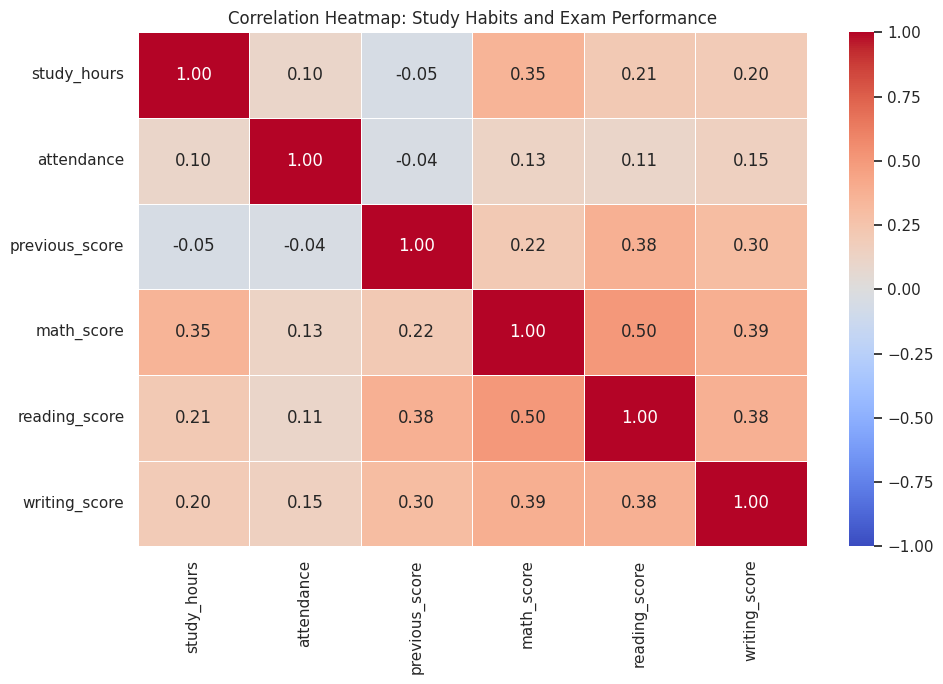

In [24]:
numeric_columns = [
    "study_hours",
    "attendance",
    "previous_score",
    "math_score",
    "reading_score",
    "writing_score"
]

correlation_matrix = df_clean[numeric_columns].corr()

display(correlation_matrix.round(2))
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Heatmap: Study Habits and Exam Performance")
plt.tight_layout()
plt.savefig("heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [25]:
print("STUDENT EXAM PERFORMANCE — KEY FINDINGS")
print("=" * 45)

print("\nAverage exam scores:")
display(df_clean[score_columns].mean().round(2).to_frame("Average Score"))

print("\nOutlier counts before capping:")
display(outlier_summary[["Feature", "Outlier Count"]])

print("\nStrongest positive correlation with each exam:")
for col in score_columns:
    correlations = correlation_matrix[col].drop(
        labels=score_columns
    )
    strongest_feature = correlations.idxmax()

    print(f"{col}: {strongest_feature} "f"(correlation = {correlations[strongest_feature]:.2f})")

STUDENT EXAM PERFORMANCE — KEY FINDINGS

Average exam scores:


,Average Score
math_score,70.01
reading_score,75.52
writing_score,74.55



Outlier counts before capping:


,Feature,Outlier Count
0,math_score,1
1,reading_score,1
2,writing_score,3



Strongest positive correlation with each exam:
math_score: study_hours (correlation = 0.35)
reading_score: previous_score (correlation = 0.38)
writing_score: previous_score (correlation = 0.30)


In [27]:
from google.colab import files

files.download("boxplot.png")
files.download("distribution_plot.png")
files.download("heatmap.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>